In [18]:
from IPython.display import Markdown, display

display(Markdown("""
# U.S. Amazon Shopping Behavior

**Business question.** Which product categories have the highest 90-day
repeat purchase rates, and how quickly do shoppers buy from them again?

**Method.** I track each shopper from their first observed purchase day in
each category. A repeat is another purchase in the same category on a later
day within 90 days. I include shoppers with a full 90-day follow-up window
and rank categories with at least 100 eligible shoppers.

**Data source.** The purchase histories come from
[Open E-commerce 1.0](https://doi.org/10.7910/DVN/YGLYDY), published by
Berke and colleagues through Harvard Dataverse. To reproduce this analysis,
upload `amazon-purchases.csv` to Colab and run the cells in order.
"""))


# U.S. Amazon Shopping Behavior

**Business question.** Which product categories have the highest 90-day
repeat purchase rates, and how quickly do shoppers buy from them again?

**Method.** I track each shopper from their first observed purchase day in
each category. A repeat is another purchase in the same category on a later
day within 90 days. I include shoppers with a full 90-day follow-up window
and rank categories with at least 100 eligible shoppers.

**Data source.** The purchase histories come from
[Open E-commerce 1.0](https://doi.org/10.7910/DVN/YGLYDY), published by
Berke and colleagues through Harvard Dataverse. To reproduce this analysis,
upload `amazon-purchases.csv` to Colab and run the cells in order.


In [19]:
import pandas as pd

sample = pd.read_csv("/content/amazon-purchases.csv", nrows=10_000)

print(sample.columns.tolist())
display(sample.head())

['Order Date', 'Purchase Price Per Unit', 'Quantity', 'Shipping Address State', 'Title', 'ASIN/ISBN (Product Code)', 'Category', 'Survey ResponseID']


,Order Date,Purchase Price Per Unit,Quantity,Shipping Address State,Title,ASIN/ISBN (Product Code),Category,Survey ResponseID
0,2018-12-04,7.98,1.0,NJ,SanDisk Ultra 16GB Class 10 SDHC UHS-I Memory ...,B0143RTB1E,FLASH_MEMORY,R_01vNIayewjIIKMF
1,2018-12-22,13.99,1.0,NJ,Betron BS10 Earphones Wired Headphones in Ear ...,B01MA1MJ6H,HEADPHONES,R_01vNIayewjIIKMF
2,2018-12-24,8.99,1.0,NJ,NaN,B078JZTFN3,NaN,R_01vNIayewjIIKMF
3,2018-12-25,10.45,1.0,NJ,Perfecto Stainless Steel Shaving Bowl. Durable...,B06XWF9HML,DISHWARE_BOWL,R_01vNIayewjIIKMF
4,2018-12-25,10.00,1.0,NJ,Proraso Shaving Cream for Men,B00837ZOI0,SHAVING_AGENT,R_01vNIayewjIIKMF


In [20]:
purchases = pd.read_csv(
    "/content/amazon-purchases.csv",
    usecols=["Survey ResponseID", "Order Date", "Category"],
    dtype="string",
).rename(columns={
    "Survey ResponseID": "shopper_id",
    "Order Date": "purchase_date",
    "Category": "category",
})

purchases["purchase_date"] = pd.to_datetime(
    purchases["purchase_date"], format="%Y-%m-%d", errors="coerce"
)

print(f"Purchase rows: {len(purchases):,}")
print(f"Unique shoppers: {purchases['shopper_id'].nunique():,}")
print(f"Unique categories: {purchases['category'].nunique():,}")

valid_dates = purchases["purchase_date"].dropna()
print(f"Date range: {valid_dates.min().date()} to {valid_dates.max().date()}")

display(purchases.isna().sum().to_frame("Missing or invalid rows"))

Purchase rows: 1,850,717
Unique shoppers: 5,027
Unique categories: 1,871
Date range: 2018-01-01 to 2024-08-15


,Missing or invalid rows
purchase_date,0
category,89458
shopper_id,0


In [21]:
# Use October 31 as the last complete month before the documented November 2022 endpoint.
analysis_end = pd.Timestamp("2022-10-31")
follow_up = pd.Timedelta(days=90)

after_documented_period = purchases["purchase_date"].ge("2022-12-01")
print(f"Rows dated after November 2022: {after_documented_period.sum():,}")

# Count one purchase day per shopper and category.
purchase_days = (
    purchases.loc[purchases["purchase_date"].le(analysis_end)]
    .dropna(subset=["shopper_id", "category", "purchase_date"])
    .drop_duplicates(subset=["shopper_id", "category", "purchase_date"])
    .sort_values("purchase_date")
    .copy()
)

print(f"Shopper-category purchase days: {len(purchase_days):,}")
display(purchase_days.head())

Rows dated after November 2022: 72,367
Shopper-category purchase days: 1,436,579


,purchase_date,category,shopper_id
813552,2018-01-01,PET_SUPPLIES,R_2fy7JSBbIRNQKLb
220837,2018-01-01,BABY_PRODUCT,R_1QLfbB3Lho273wG
220836,2018-01-01,CELLULAR_PHONE_CASE,R_1QLfbB3Lho273wG
1813281,2018-01-01,ABIS_BOOK,R_wWRN3CSxwSpXoUp
133286,2018-01-01,CHARGING_ADAPTER,R_1IaQCAaU1CcbXWO


In [22]:
# Find the next purchase day for each shopper in the same category.
purchase_days["next_purchase_date"] = (
    purchase_days.groupby(["shopper_id", "category"], sort=False)["purchase_date"]
    .shift(-1)
)

# Keep first observed purchases with a full 90 days of follow-up.
first_purchases = purchase_days.drop_duplicates(["shopper_id", "category"])
eligible = first_purchases.loc[
    first_purchases["purchase_date"].le(analysis_end - follow_up)
].copy()

days_to_repeat = eligible["next_purchase_date"] - eligible["purchase_date"]
eligible["repeated_within_90_days"] = days_to_repeat.le(follow_up)

print(f"Eligible shopper–category pairs: {len(eligible):,}")
print(f"Pairs with a repeat within 90 days: {eligible['repeated_within_90_days'].sum():,}")

Eligible shopper–category pairs: 601,175
Pairs with a repeat within 90 days: 76,368


In [23]:
category_summary = eligible.groupby("category").agg(
    eligible_shoppers=("shopper_id", "size"),
    repeat_shoppers=("repeated_within_90_days", "sum"),
)

category_summary["repeat_rate_pct"] = (
    100 * category_summary["repeat_shoppers"]
    / category_summary["eligible_shoppers"]
)

# Rank categories with at least 100 eligible shoppers.
ranking = (
    category_summary.loc[category_summary["eligible_shoppers"].ge(100)]
    .sort_values("repeat_rate_pct", ascending=False)
)

display(ranking.head(10).round(1))

,eligible_shoppers,repeat_shoppers,repeat_rate_pct
category,,,
PET_FOOD,1944,871,44.8
BREAD,519,224,43.2
THERMOPLASTIC_FILAMENT,163,69,42.3
POULTRY,442,185,41.9
EGG,224,92,41.1
ABIS_BOOK,4144,1700,41.0
DAIRY_BASED_ICE_CREAM,279,112,40.1
MEAT,536,215,40.1
DAIRY_BASED_YOGURT,243,97,39.9


## Top 10 Categories by 90-Day Repeat Purchase Rate

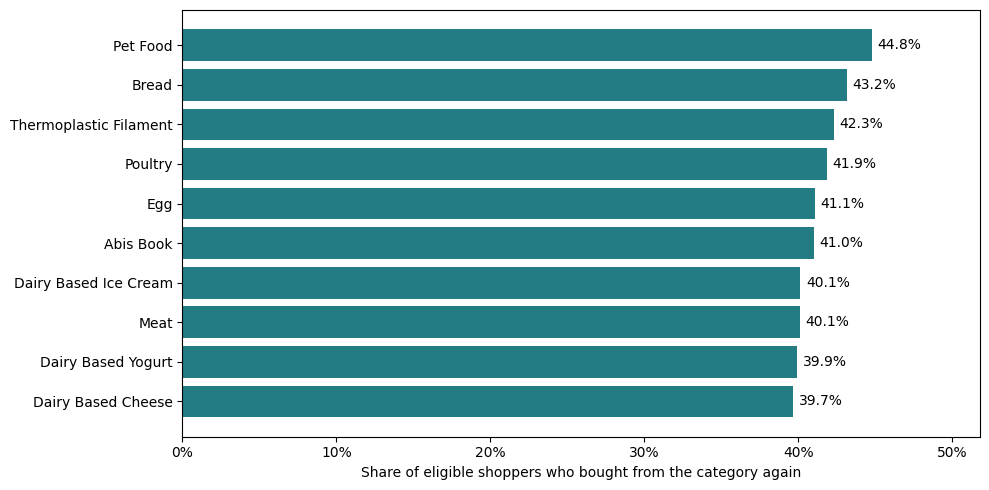

**Finding:** Pet food led the ranking at **44.8%**, with 871 of 1,944 eligible shoppers buying from the category again within 90 days. The `ABIS_BOOK` category had the most repeat shoppers among the ten categories shown (**1,700**), with a repeat rate of **41.0%**.

In [24]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

display(Markdown("## Top 10 Categories by 90-Day Repeat Purchase Rate"))

# Reverse the chart order so the highest rate appears at the top.
top_categories = ranking.head(10).iloc[::-1]
labels = top_categories.index.str.replace("_", " ", regex=False).str.title()
rates = top_categories["repeat_rate_pct"]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(labels, rates, color="#237B83")

ax.bar_label(bars, labels=[f"{rate:.1f}%" for rate in rates], padding=4)
ax.set_xlabel("Share of eligible shoppers who bought from the category again")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlim(0, rates.max() + 7)

fig.tight_layout()
plt.show()

display(Markdown(
    "**Finding:** Pet food led the ranking at **44.8%**, with 871 of "
    "1,944 eligible shoppers buying from the category again within 90 days. "
    "The `ABIS_BOOK` category had the most repeat shoppers among the ten "
    "categories shown (**1,700**), with a repeat rate of **41.0%**."
))

In [29]:
display(Markdown("## How Soon Do Shoppers Buy Again?"))

category_labels = {
    "PET_FOOD": "Pet food",
    "BREAD": "Bread",
    "ABIS_BOOK": "Books",
}

selected = eligible.loc[
    eligible["category"].isin(category_labels)
].copy()

days_to_repeat = (
    selected["next_purchase_date"] - selected["purchase_date"]
).dt.days

# Use the same eligible shoppers at every checkpoint.
for day in (30, 60, 90):
    selected[f"Day {day}"] = days_to_repeat.between(1, day)

repeat_timing = (
    selected.groupby("category")[["Day 30", "Day 60", "Day 90"]]
    .mean()
    .mul(100)
    .reindex(category_labels)
    .rename(index=category_labels)
)

display(repeat_timing.style.format("{:.1f}%"))

pet_food = repeat_timing.loc["Pet food"]
display(Markdown(
    f"**Finding:** By day 30, **{pet_food['Day 30']:.1f}%** of eligible "
    f"pet food shoppers had bought from the category again. By day 90, "
    f"that share reached **{pet_food['Day 90']:.1f}%**. Each column shows "
    "the cumulative share of eligible shoppers who had returned by that day."
))

## How Soon Do Shoppers Buy Again?

,Day 30,Day 60,Day 90
category,,,
Pet food,22.9%,36.7%,44.8%
Bread,28.7%,38.0%,43.2%
Books,23.2%,33.8%,41.0%


**Finding:** By day 30, **22.9%** of eligible pet food shoppers had bought from the category again. By day 90, that share reached **44.8%**. Each column shows the cumulative share of eligible shoppers who had returned by that day.

In [30]:
display(Markdown("## Do Repeat Purchase Rates Hold Across Years?"))

# Group shoppers by the year of their first observed purchase in each category.
yearly_purchases = selected.assign(
    first_purchase_year=selected["purchase_date"].dt.year
)

yearly_summary = (
    yearly_purchases.groupby(["first_purchase_year", "category"])
    .agg(
        eligible_shoppers=("shopper_id", "size"),
        repeat_rate=("repeated_within_90_days", "mean"),
    )
    .reset_index()
)

yearly_summary["category"] = yearly_summary["category"].map(category_labels)

yearly_table = yearly_summary.pivot(
    index="first_purchase_year",
    columns="category",
    values=["repeat_rate", "eligible_shoppers"],
).rename(columns={
    "repeat_rate": "90-day repeat rate",
    "eligible_shoppers": "Eligible shoppers",
})

display(yearly_table.style.format({
    **{("90-day repeat rate", name): "{:.1%}" for name in category_labels.values()},
    **{("Eligible shoppers", name): "{:,.0f}" for name in category_labels.values()},
}, na_rep="—"))

display(Markdown(
    "**Reading the table:** Each year refers to the first observed purchase "
    "in that category. The 2022 group covers part of the year because each "
    "shopper needed a full 90 days of follow-up before the October cutoff."
))

## Do Repeat Purchase Rates Hold Across Years?

**Reading the table:** Each year refers to the first observed purchase in that category. The 2022 group covers part of the year because each shopper needed a full 90 days of follow-up before the October cutoff.

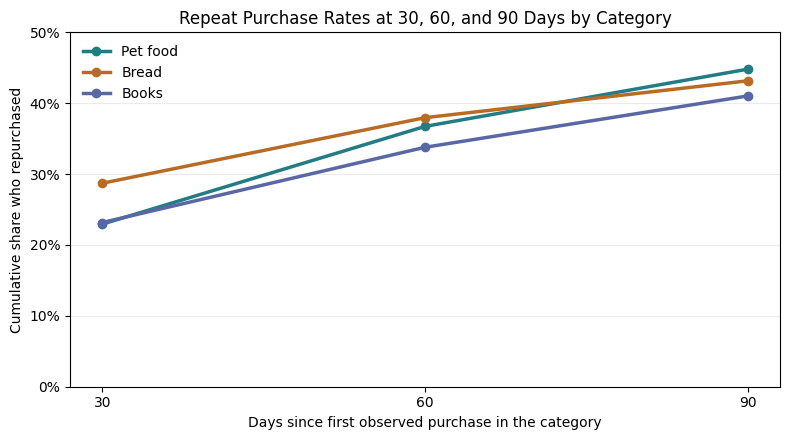

**Finding:** Bread led at day 30 (**28.7%** vs. **22.9%** for pet food). By day 90, pet food had pulled ahead (**44.8%** vs. **43.2%** for bread). Books reached **41.0%** by day 90.

In [34]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

days = [30, 60, 90]
colors = {"Pet food": "#237B83", "Bread": "#B86B25", "Books": "#5968A5"}

fig, ax = plt.subplots(figsize=(8, 4.5))

for category, rates in repeat_timing.iterrows():
    ax.plot(
        days, rates, marker="o", linewidth=2.5,
        color=colors[category], label=category,
    )

ax.set_xticks(days)
ax.set_xlabel("Days since first observed purchase in the category")
ax.set_ylabel("Cumulative share who repurchased")
ax.set_ylim(0, 50)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Repeat Purchase Rates at 30, 60, and 90 Days by Category")
fig.tight_layout()
plt.show()

display(Markdown(
    "**Finding:** Bread led at day 30 (**28.7%** vs. **22.9%** for pet food). "
    "By day 90, pet food had pulled ahead (**44.8%** vs. **43.2%** for bread). "
    "Books reached **41.0%** by day 90."
))

In [27]:
display(Markdown("""
## Key Findings and Business Implications

- **Pet food led the overall ranking.** Within 90 days of their first
  observed pet food purchase, 44.8% of eligible shoppers bought from the
  category again.
- **Bread shoppers returned sooner.** By day 30, 28.7% had bought bread
  again, compared with 22.9% for pet food. Bread also had a higher
  90-day repeat rate than pet food in 2020 and 2021.

**Business implication.** Pet food is a candidate for a reorder reminder
test. About 23% of eligible pet food shoppers had already returned by day 30,
so I’d test a day-30 reminder among shoppers who haven’t repurchased yet.
A holdout group would help measure whether the reminder generates additional
purchases.

**Limitations.** Purchase histories start in 2018, so some shoppers in the
2018 group may have bought from the category before the dataset began.
The 2022 group covers only part of the year, and some yearly groups are
small. The findings describe shoppers in this dataset.
"""))


## Key Findings and Business Implications

- **Pet food led the overall ranking.** Within 90 days of their first
  observed pet food purchase, 44.8% of eligible shoppers bought from the
  category again.
- **Bread shoppers returned sooner.** By day 30, 28.7% had bought bread
  again, compared with 22.9% for pet food. Bread also had a higher
  90-day repeat rate than pet food in 2020 and 2021.

**Business implication.** Pet food is a candidate for a reorder reminder
test. About 23% of eligible pet food shoppers had already returned by day 30,
so I’d test a day-30 reminder among shoppers who haven’t repurchased yet.
A holdout group would help measure whether the reminder generates additional
purchases.

**Limitations.** Purchase histories start in 2018, so some shoppers in the
2018 group may have bought from the category before the dataset began.
The 2022 group covers only part of the year, and some yearly groups are
small. The findings describe shoppers in this dataset.
